
# Censo Demográfico 2022: um retrato da população brasileira

**Disciplina:** Linguagem de Programação

**Alunos:** Lucas Lima Ribeiro e Gustavo Madruga 

**Professor:** Alexandre Neves Louzada

**Semestre:** 2026.2

**Instituição:** Unilasalle

---

## 1. Introdução

O Censo Demográfico é uma das principais fontes de informações sobre a população brasileira. Realizado pelo Instituto Brasileiro de Geografia e Estatística (IBGE), permite conhecer características da população, como distribuição por sexo, idade e localização geográfica.

Este projeto tem como objetivo analisar dados do Censo Demográfico 2022, buscando compreender a composição da população brasileira e identificar diferenças entre as regiões e unidades da Federação.

A análise utiliza dados da Tabela 9514 do IBGE, que apresenta informações sobre a população residente por sexo, idade e forma de declaração da idade.

## 2. Objetivos da análise

- Identificar a distribuição da população brasileira por sexo.
- Analisar a composição da população por grupos de idade.
- Comparar a distribuição populacional entre regiões e estados.
- Explorar padrões e diferenças na estrutura demográfica brasileira.


In [15]:

# 3. Importação das bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configurações de visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


In [16]:

# 4. Carregamento dos dados processados

# Identifica a pasta principal do projeto
PASTA_PROJETO = Path.cwd()

if not (PASTA_PROJETO / "data").exists():
    PASTA_PROJETO = PASTA_PROJETO.parent

# Caminhos dos arquivos
arquivo_populacao = (
    PASTA_PROJETO / "data" / "processed" / "populacao_2022.csv.gz"
)

arquivo_percentual = (
    PASTA_PROJETO / "data" / "processed" / "percentual_populacao_2022.csv.gz"
)

# Leitura dos arquivos
df_populacao = pd.read_csv(arquivo_populacao)
df_percentual = pd.read_csv(arquivo_percentual)

print("Dados carregados com sucesso!")
print("\nBase de população absoluta:", df_populacao.shape)
print("Base de percentual:", df_percentual.shape)


Dados carregados com sucesso!

Base de população absoluta: (2178, 6)
Base de percentual: (2178, 6)


In [17]:

# 5. Visualização inicial dos dados

print("PRIMEIROS REGISTROS — POPULAÇÃO ABSOLUTA")
display(df_populacao.head(10))

print("\nPRIMEIROS REGISTROS — PERCENTUAL")
display(df_percentual.head(10))


PRIMEIROS REGISTROS — POPULAÇÃO ABSOLUTA


,localidade,forma_declaracao_idade,ano,sexo,faixa_etaria,valor
0,Brasil,Total,2022,Total,Total,203080756
1,Brasil,Total,2022,Total,0 a 4 anos,12704860
2,Brasil,Total,2022,Total,5 a 9 anos,13749440
3,Brasil,Total,2022,Total,10 a 14 anos,13674961
4,Brasil,Total,2022,Total,15 a 19 anos,14375942
5,Brasil,Total,2022,Total,20 a 24 anos,15466463
6,Brasil,Total,2022,Total,25 a 29 anos,15469723
7,Brasil,Total,2022,Total,30 a 34 anos,15473117
8,Brasil,Total,2022,Total,35 a 39 anos,16172791
9,Brasil,Total,2022,Total,40 a 44 anos,16072170



PRIMEIROS REGISTROS — PERCENTUAL


,localidade,forma_declaracao_idade,ano,sexo,faixa_etaria,valor
0,Brasil,Total,2022,Total,Total,100.00
1,Brasil,Total,2022,Total,0 a 4 anos,6.26
2,Brasil,Total,2022,Total,5 a 9 anos,6.77
3,Brasil,Total,2022,Total,10 a 14 anos,6.73
4,Brasil,Total,2022,Total,15 a 19 anos,7.08
5,Brasil,Total,2022,Total,20 a 24 anos,7.62
6,Brasil,Total,2022,Total,25 a 29 anos,7.62
7,Brasil,Total,2022,Total,30 a 34 anos,7.62
8,Brasil,Total,2022,Total,35 a 39 anos,7.96
9,Brasil,Total,2022,Total,40 a 44 anos,7.91


In [18]:

# 6. Verificação da qualidade dos dados

print("INFORMAÇÕES DA BASE DE POPULAÇÃO")
df_populacao.info()

print("\nVALORES AUSENTES — POPULAÇÃO")
print(df_populacao.isnull().sum())

print("\nREGISTROS DUPLICADOS — POPULAÇÃO")
print(df_populacao.duplicated().sum())

print("\nINFORMAÇÕES DA BASE PERCENTUAL")
df_percentual.info()

print("\nVALORES AUSENTES — PERCENTUAL")
print(df_percentual.isnull().sum())

print("\nREGISTROS DUPLICADOS — PERCENTUAL")
print(df_percentual.duplicated().sum())


INFORMAÇÕES DA BASE DE POPULAÇÃO
<class 'pandas.DataFrame'>
RangeIndex: 2178 entries, 0 to 2177
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   localidade              2178 non-null   str  
 1   forma_declaracao_idade  2178 non-null   str  
 2   ano                     2178 non-null   int64
 3   sexo                    2178 non-null   str  
 4   faixa_etaria            2178 non-null   str  
 5   valor                   2178 non-null   int64
dtypes: int64(2), str(4)
memory usage: 102.2 KB

VALORES AUSENTES — POPULAÇÃO
localidade                0
forma_declaracao_idade    0
ano                       0
sexo                      0
faixa_etaria              0
valor                     0
dtype: int64

REGISTROS DUPLICADOS — POPULAÇÃO
0

INFORMAÇÕES DA BASE PERCENTUAL
<class 'pandas.DataFrame'>
RangeIndex: 2178 entries, 0 to 2177
Data columns (total 6 columns):
 #   Column                  Non-Null Coun

In [19]:

# 7. Análise da distribuição percentual da população brasileira

# Filtra apenas os dados do Brasil
brasil_percentual = df_percentual[
    (df_percentual["localidade"] == "Brasil") &
    (df_percentual["faixa_etaria"] != "Total")
]

# Soma os percentuais por sexo
distribuicao_sexo = (
    brasil_percentual
    .groupby("sexo")["valor"]
    .sum()
    .reset_index()
)

print("DISTRIBUIÇÃO PERCENTUAL DA POPULAÇÃO POR SEXO")
display(distribuicao_sexo)

# Verifica os totais gerais apresentados pelo IBGE
print("\nPERCENTUAIS TOTAIS INFORMADOS NA BASE")

display(
    df_percentual[
        (df_percentual["localidade"] == "Brasil") &
        (df_percentual["faixa_etaria"] == "Total")
    ][["sexo", "valor"]]
)


DISTRIBUIÇÃO PERCENTUAL DA POPULAÇÃO POR SEXO


,sexo,valor
0,Homens,48.51
1,Mulheres,51.48
2,Total,100.00



PERCENTUAIS TOTAIS INFORMADOS NA BASE


,sexo,valor
0,Total,100.00
22,Homens,48.52
44,Mulheres,51.48


In [20]:

# 8. Estatísticas descritivas da população brasileira

# Seleciona os dados do Brasil
brasil = df_populacao[
    (df_populacao["localidade"] == "Brasil") &
    (df_populacao["sexo"] == "Total")
].copy()

# Remove a linha do total geral para analisar as faixas etárias
brasil_faixas = brasil[
    brasil["faixa_etaria"] != "Total"
]

print("ESTATÍSTICAS DESCRITIVAS DA POPULAÇÃO POR FAIXA ETÁRIA")

display(brasil_faixas["valor"].describe())

print("\nFAIXAS ETÁRIAS COM MAIOR POPULAÇÃO")

display(
    brasil_faixas
    .sort_values("valor", ascending=False)
    [["faixa_etaria", "valor"]]
    .head(10)
)


ESTATÍSTICAS DESCRITIVAS DA POPULAÇÃO POR FAIXA ETÁRIA


count    2.100000e+01
mean     9.670512e+06
std      5.979055e+06
min      3.781400e+04
25%      3.847379e+06
50%      1.259858e+07
75%      1.437594e+07
max      1.617279e+07
Name: valor, dtype: float64


FAIXAS ETÁRIAS COM MAIOR POPULAÇÃO


,faixa_etaria,valor
8,35 a 39 anos,16172791
9,40 a 44 anos,16072170
7,30 a 34 anos,15473117
6,25 a 29 anos,15469723
5,20 a 24 anos,15466463
4,15 a 19 anos,14375942
2,5 a 9 anos,13749440
3,10 a 14 anos,13674961
10,45 a 49 anos,13640112
1,0 a 4 anos,12704860


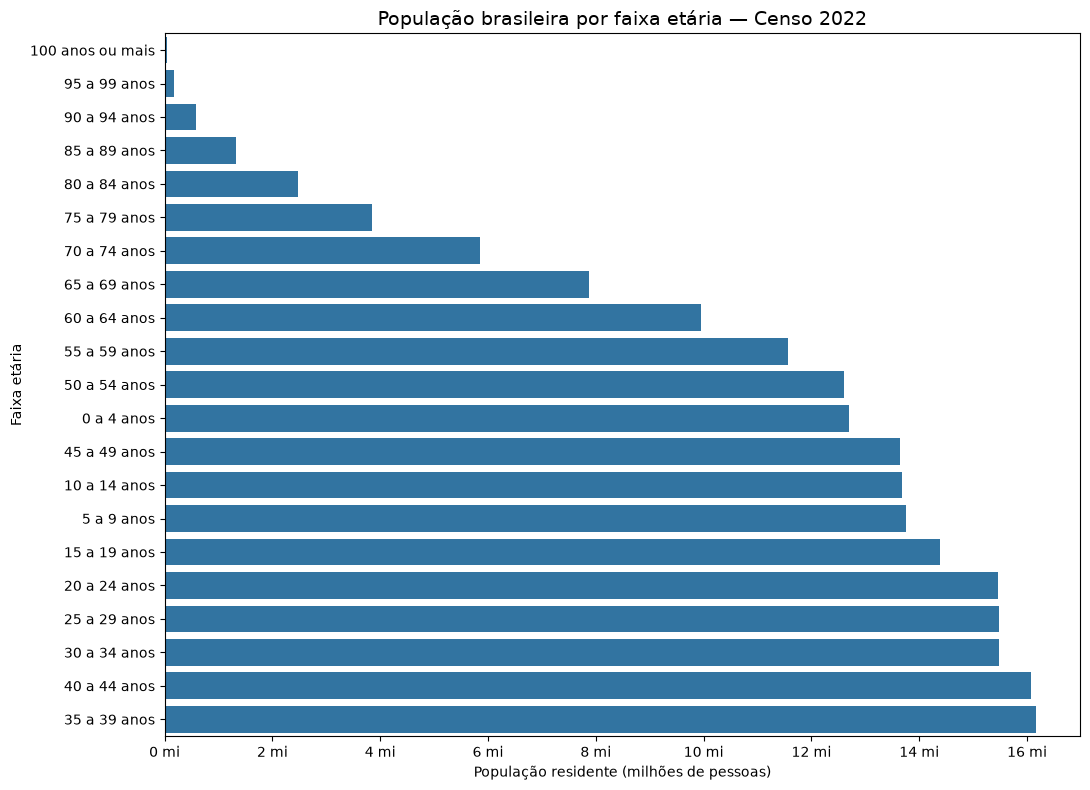

In [21]:

# 9. Gráfico da população brasileira por faixa etária

plt.figure(figsize=(11, 8))

dados_grafico = brasil_faixas.sort_values(
    "valor",
    ascending=True
)

sns.barplot(
    data=dados_grafico,
    x="valor",
    y="faixa_etaria"
)

plt.title(
    "População brasileira por faixa etária — Censo 2022",
    fontsize=14
)

plt.xlabel("População residente (milhões de pessoas)")
plt.ylabel("Faixa etária")

# Apresenta os valores em milhões
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x / 1_000_000:.0f} mi")
)

plt.tight_layout()
plt.show()



### Análise da distribuição por faixa etária

A análise dos dados do Censo Demográfico 2022 demonstra uma concentração populacional nas faixas etárias adultas. O grupo de 35 a 39 anos apresenta o maior número de habitantes, com 16.172.791 pessoas, seguido pelo grupo de 40 a 44 anos, com 16.072.170 pessoas.

Esses resultados ajudam a compreender a composição etária da população brasileira e permitem observar como os diferentes grupos de idade estão distribuídos no país.


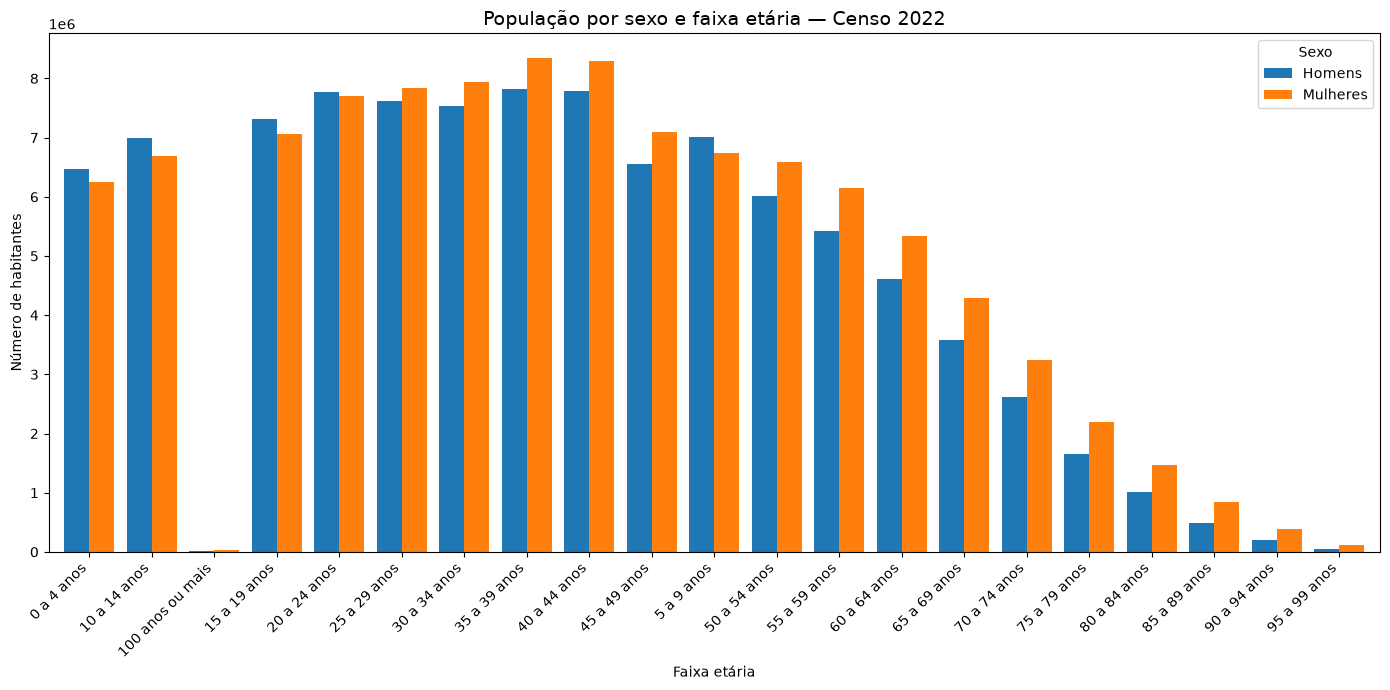

In [22]:

# 10. Comparação da população por sexo e faixa etária

# Seleciona os dados do Brasil, excluindo os totais gerais
comparacao_sexo = df_populacao[
    (df_populacao["localidade"] == "Brasil") &
    (df_populacao["sexo"].isin(["Homens", "Mulheres"])) &
    (df_populacao["faixa_etaria"] != "Total")
].copy()

# Organiza os dados em colunas separadas por sexo
tabela_sexo = comparacao_sexo.pivot(
    index="faixa_etaria",
    columns="sexo",
    values="valor"
)

# Criação do gráfico
tabela_sexo.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title(
    "População por sexo e faixa etária — Censo 2022",
    fontsize=14
)

plt.xlabel("Faixa etária")
plt.ylabel("Número de habitantes")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Sexo")
plt.tight_layout()
plt.show()



### Comparação da população por sexo e faixa etária

A comparação entre homens e mulheres permite observar diferenças na composição demográfica brasileira. De maneira geral, os dados mostram uma participação feminina ligeiramente superior na população total.

A análise por faixa etária também permite identificar como essa distribuição se modifica ao longo da idade. Essas diferenças ajudam a compreender a estrutura populacional e podem estar relacionadas a fatores demográficos, como expectativa de vida e mortalidade.

O gráfico facilita a visualização dessas diferenças e complementa a análise da distribuição etária da população brasileira.


POPULAÇÃO TOTAL POR GRANDE REGIÃO


,localidade,valor
198,Sudeste,84840113
132,Nordeste,54658515
264,Sul,29937706
66,Norte,17354884
330,Centro-Oeste,16289538


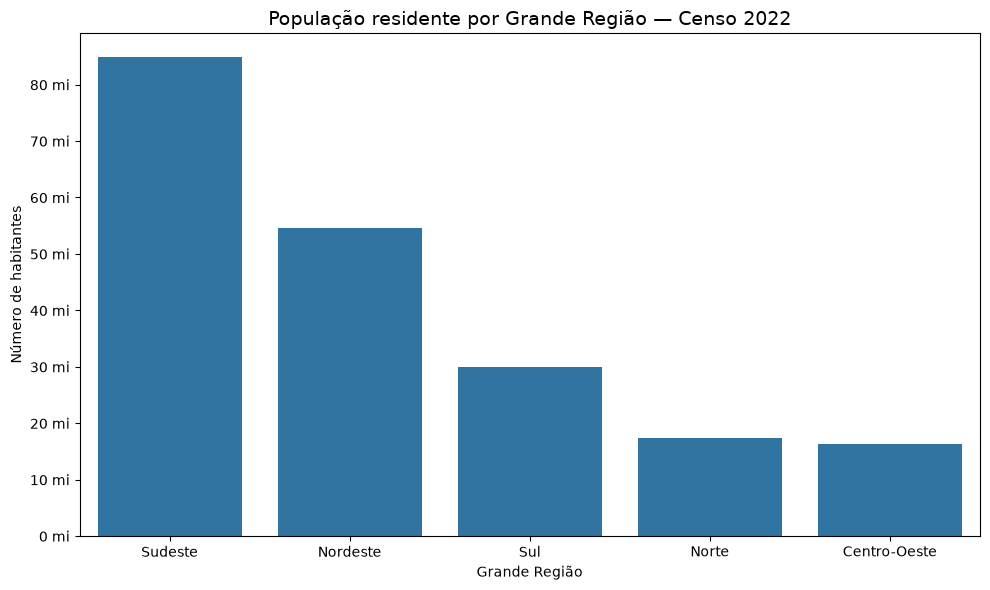

In [23]:

# 12. População por Grande Região

regioes = [
    "Norte",
    "Nordeste",
    "Sudeste",
    "Sul",
    "Centro-Oeste"
]

dados_regioes = df_populacao[
    (df_populacao["localidade"].isin(regioes)) &
    (df_populacao["sexo"] == "Total") &
    (df_populacao["faixa_etaria"] == "Total")
].copy()

# Ordena as regiões da maior para a menor população
dados_regioes = dados_regioes.sort_values(
    "valor",
    ascending=False
)

print("POPULAÇÃO TOTAL POR GRANDE REGIÃO")
display(dados_regioes[["localidade", "valor"]])

# Gráfico
plt.figure(figsize=(10, 6))

sns.barplot(
    data=dados_regioes,
    x="localidade",
    y="valor"
)

plt.title(
    "População residente por Grande Região — Censo 2022",
    fontsize=14
)

plt.xlabel("Grande Região")
plt.ylabel("Número de habitantes")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x / 1_000_000:.0f} mi")
)

plt.tight_layout()
plt.show()



### Distribuição da população por Grande Região

A análise da população por Grande Região permite observar que os habitantes brasileiros estão distribuídos de maneira desigual pelo território nacional.

Essa distribuição evidencia diferenças na concentração populacional entre as regiões, contribuindo para compreender aspectos da organização territorial do Brasil.

A comparação regional também é importante para o planejamento de políticas públicas, pois permite identificar onde está concentrada a maior parcela da população e quais regiões possuem menor participação no total nacional.


In [24]:

# 14. Ranking dos estados mais populosos

# Seleciona os dados de população total por estado
dados_estados = df_populacao[
    (df_populacao["sexo"] == "Total") &
    (df_populacao["faixa_etaria"] == "Total")
].copy()

# Remove Brasil e as cinco Grandes Regiões
dados_estados = dados_estados[
    ~dados_estados["localidade"].isin(
        ["Brasil", "Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]
    )
]

# Ordena do maior para o menor
ranking_estados = dados_estados.sort_values(
    "valor",
    ascending=False
)

print("10 ESTADOS MAIS POPULOSOS")
display(ranking_estados[["localidade", "valor"]].head(10))

print("\n10 ESTADOS MENOS POPULOSOS")
display(ranking_estados[["localidade", "valor"]].tail(10))


10 ESTADOS MAIS POPULOSOS


,localidade,valor
1650,São Paulo,44411238
1452,Minas Gerais,20539989
1584,Rio de Janeiro,16055174
1386,Bahia,14141626
1716,Paraná,11444380
1848,Rio Grande do Sul,10882965
1188,Pernambuco,9058931
990,Ceará,8794957
660,Pará,8120131
1782,Santa Catarina,7610361



10 ESTADOS MENOS POPULOSOS


,localidade,valor
924,Piauí,3271199
1254,Alagoas,3127683
2112,Distrito Federal,2817381
1914,Mato Grosso do Sul,2757013
1320,Sergipe,2210004
396,Rondônia,1581196
792,Tocantins,1511460
462,Acre,830018
726,Amapá,733759
594,Roraima,636707


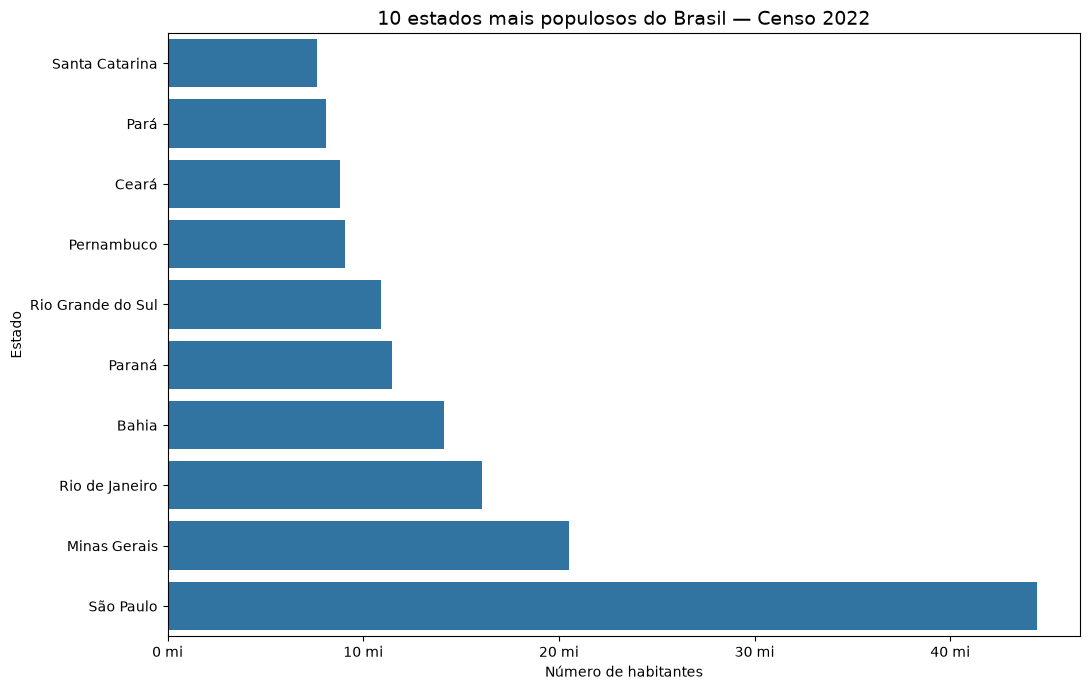

In [25]:

# 15. Gráfico dos 10 estados mais populosos

top_10_estados = ranking_estados.head(10).sort_values(
    "valor",
    ascending=True
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_10_estados,
    x="valor",
    y="localidade"
)

plt.title(
    "10 estados mais populosos do Brasil — Censo 2022",
    fontsize=14
)

plt.xlabel("Número de habitantes")
plt.ylabel("Estado")

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x / 1_000_000:.0f} mi")
)

plt.tight_layout()
plt.show()



### Estados mais populosos do Brasil

O ranking dos dez estados mais populosos permite identificar como a população brasileira está distribuída entre as unidades da Federação.

A análise demonstra que existe uma concentração populacional em determinados estados, evidenciando diferenças demográficas importantes entre as unidades federativas.

Essa informação é relevante para compreender a distribuição territorial da população e também pode contribuir para discussões sobre planejamento urbano, infraestrutura e políticas públicas.


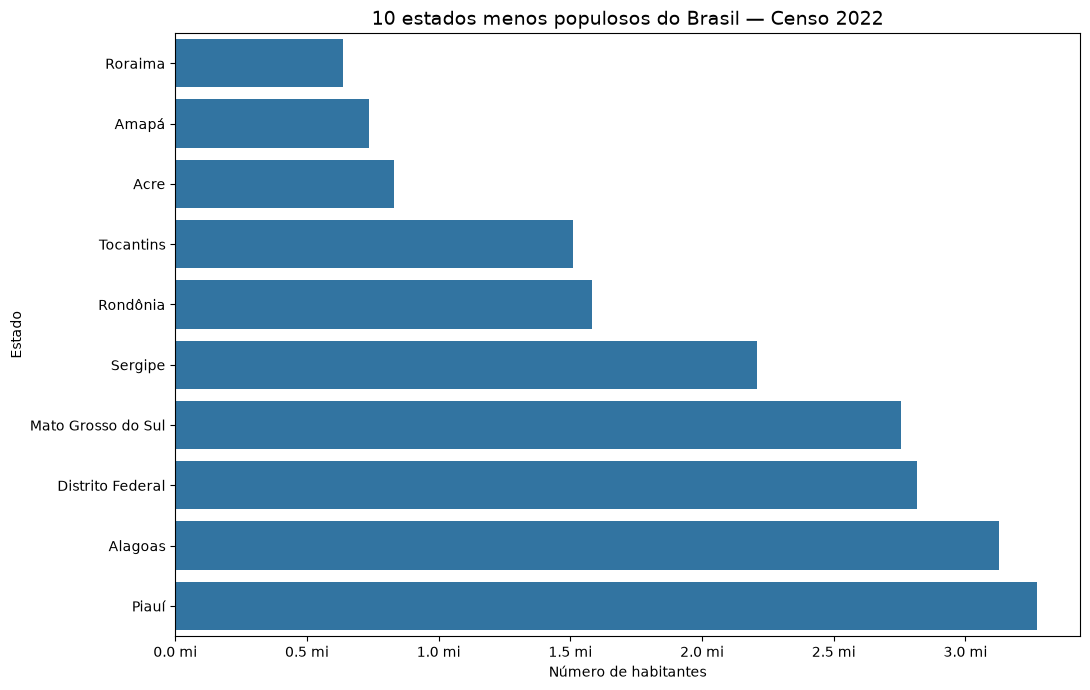

In [26]:

# 17. Gráfico dos 10 estados menos populosos

bottom_10_estados = ranking_estados.tail(10).sort_values(
    "valor",
    ascending=True
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=bottom_10_estados,
    x="valor",
    y="localidade"
)

plt.title(
    "10 estados menos populosos do Brasil — Censo 2022",
    fontsize=14
)

plt.xlabel("Número de habitantes")
plt.ylabel("Estado")

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f} mi")
)

plt.tight_layout()
plt.show()


In [28]:

# 18. Indicadores gerais da população brasileira

# Seleciona o total da população brasileira
total_brasil = df_populacao[
    (df_populacao["localidade"] == "Brasil") &
    (df_populacao["sexo"] == "Total") &
    (df_populacao["faixa_etaria"] == "Total")
]["valor"].iloc[0]

# Seleciona o total de homens
total_homens = df_populacao[
    (df_populacao["localidade"] == "Brasil") &
    (df_populacao["sexo"] == "Homens") &
    (df_populacao["faixa_etaria"] == "Total")
]["valor"].iloc[0]

# Seleciona o total de mulheres
total_mulheres = df_populacao[
    (df_populacao["localidade"] == "Brasil") &
    (df_populacao["sexo"] == "Mulheres") &
    (df_populacao["faixa_etaria"] == "Total")
]["valor"].iloc[0]

# Calcula a diferença entre homens e mulheres
diferenca = abs(total_mulheres - total_homens)

# Calcula os percentuais
percentual_homens = (total_homens / total_brasil) * 100
percentual_mulheres = (total_mulheres / total_brasil) * 100

# Organiza os indicadores em uma tabela
indicadores = pd.DataFrame({
    "Indicador": [
        "População total",
        "Total de homens",
        "Total de mulheres",
        "Diferença entre mulheres e homens",
        "Percentual de homens",
        "Percentual de mulheres"
    ],
    "Resultado": [
        total_brasil,
        total_homens,
        total_mulheres,
        diferenca,
        f"{percentual_homens:.2f}%",
        f"{percentual_mulheres:.2f}%"
    ]
})

print("INDICADORES GERAIS — CENSO DEMOGRÁFICO 2022")
display(indicadores)

# Identifica a região mais populosa
regiao_mais_populosa = dados_regioes.iloc[0]

print("\nREGIÃO MAIS POPULOSA:")
print(regiao_mais_populosa["localidade"])
print(f'{regiao_mais_populosa["valor"]:,.0f} habitantes'.replace(",", "."))

# Identifica a faixa etária com maior população
faixa_mais_populosa = brasil_faixas.sort_values(
    "valor",
    ascending=False
).iloc[0]

print("\nFAIXA ETÁRIA MAIS POPULOSA:")
print(faixa_mais_populosa["faixa_etaria"])
print(f'{faixa_mais_populosa["valor"]:,.0f} habitantes'.replace(",", "."))


INDICADORES GERAIS — CENSO DEMOGRÁFICO 2022


,Indicador,Resultado
0,População total,203080756
1,Total de homens,98532431
2,Total de mulheres,104548325
3,Diferença entre mulheres e homens,6015894
4,Percentual de homens,48.52%
5,Percentual de mulheres,51.48%



REGIÃO MAIS POPULOSA:
Sudeste
84.840.113 habitantes

FAIXA ETÁRIA MAIS POPULOSA:
35 a 39 anos
16.172.791 habitantes



## 19. Síntese dos principais resultados

A análise dos dados do Censo Demográfico 2022 permitiu identificar algumas características importantes da população brasileira.

A população total identificada na base foi de **203.080.756 habitantes**. Em relação à distribuição por sexo, observou-se que as mulheres representam 51,48% da população, enquanto os homens correspondem a 48,52%. A diferença entre os dois grupos é de 6.015.894 habitantes, indicando uma maior participação feminina.

Na análise por faixa etária, o grupo de **35 a 39 anos** apresentou a maior concentração populacional, com 16.172.791 habitantes. Esse resultado demonstra a relevância dos grupos adultos na composição demográfica analisada.

Em relação à distribuição geográfica, a região **Sudeste** apresentou a maior população, totalizando 84.840.113 habitantes.

Os resultados respondem às perguntas de pesquisa propostas, permitindo observar diferenças na distribuição da população por sexo, idade e localização geográfica.



## 20. Conclusão

A realização desta análise exploratória possibilitou conhecer melhor a estrutura demográfica da população brasileira a partir dos dados do Censo Demográfico 2022, disponibilizados pelo IBGE.

Durante o desenvolvimento do projeto, foram utilizadas ferramentas de programação e análise de dados em Python para organizar, tratar, explorar e visualizar as informações. Esse processo permitiu transformar uma base de dados extensa em resultados mais compreensíveis, facilitando a identificação de padrões populacionais.

Entre os principais resultados, destacam-se a maior participação feminina na população brasileira, a concentração populacional na faixa etária de 35 a 39 anos e a predominância da região Sudeste em termos de população residente.

Além dos resultados estatísticos, o projeto proporcionou a aplicação prática de conhecimentos relacionados à manipulação de dados, análise exploratória e construção de visualizações. O desenvolvimento do dashboard interativo também ampliou as possibilidades de consulta e interpretação das informações.

Como limitação, a análise foi realizada com base em uma tabela específica do Censo Demográfico 2022, não abrangendo todas as dimensões disponíveis na pesquisa. Como possibilidade de continuidade, outras variáveis demográficas e socioeconômicas poderão ser incorporadas em estudos futuros.

Conclui-se que a utilização de ferramentas de análise e visualização de dados representa um recurso importante para compreender informações populacionais e apoiar a produção de conhecimento.
